# YOLOv8s-seg for IAN Canal & Mandibular Third Molar Segmentation
## Automated Risk Assessment in Dental Panoramic Tomography

**Author:** Minu  
**Institution:** IIT (20210902) & RGU Aberdeen (2236755)  
**Supervisor:** Dr. Prasan Yapa  

This notebook implements YOLOv8s-seg for simultaneous segmentation of IAN canal and mandibular third molars as part of a unified multi-task learning framework for pre-operative risk assessment.

---

## 1. Setup & Installation

In [ ]:
# Install required packages
!pip install ultralytics
!pip install opencv-python-headless
!pip install albumentations
!pip install scikit-image
!pip install seaborn
!pip install plotly

# Verify installation
import ultralytics
ultralytics.checks()

print(f"Ultralytics version: {ultralytics.__version__}")

Ultralytics 8.4.9 🚀 Python-3.12.12 torch-2.9.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 38.7/112.6 GB disk)
Ultralytics version: 8.4.9


## 2. Mount Google Drive & Import Libraries

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
import json
import shutil
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import seaborn as sns
from PIL import Image
import cv2
from pathlib import Path
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split
import yaml

# Ultralytics
from ultralytics import YOLO

# Set seeds for reproducibility
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)

set_seed(42)

print("✓ All libraries imported successfully!")

✓ All libraries imported successfully!


## 3. Dataset Configuration

**⚠️ IMPORTANT: Update these paths to match your Google Drive structure**

In [ ]:
# ================================================================================
# 🔴 UPDATE THESE PATHS TO YOUR GOOGLE DRIVE LOCATIONS
# ================================================================================

# Path to your COCO format annotation JSON file
COCO_JSON_PATH = '/content/drive/MyDrive/FINAL_YEAR/DPT_1234new/Seg_Anno/batch1-10.json'

# Path to your DPT images directory
IMAGE_DIR = '/content/drive/MyDrive/FINAL_YEAR/DPT_1234new'

# Output directory for processed dataset (will be created in Colab local storage for speed)
OUTPUT_DIR = '/content/yolo_dataset'

# Path to save trained models (on Google Drive for persistence)
MODEL_SAVE_DIR = '/content/drive/MyDrive/FINAL_YEAR/Models/YOLOv8s_seg'

# ================================================================================

# Create necessary directories
os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(MODEL_SAVE_DIR, exist_ok=True)

print(f"✓ COCO JSON: {COCO_JSON_PATH}")
print(f"✓ Images: {IMAGE_DIR}")
print(f"✓ Output: {OUTPUT_DIR}")
print(f"✓ Models will be saved to: {MODEL_SAVE_DIR}")

✓ COCO JSON: /content/drive/MyDrive/FINAL_YEAR/DPT_1234new/Seg_Anno/batch1-10.json
✓ Images: /content/drive/MyDrive/FINAL_YEAR/DPT_1234new
✓ Output: /content/yolo_dataset
✓ Models will be saved to: /content/drive/MyDrive/FINAL_YEAR/Models/YOLOv8s_seg


## 4. Load & Analyze COCO Annotations

In [ ]:
# Load COCO format JSON
with open(COCO_JSON_PATH, 'r') as f:
    coco_data = json.load(f)

print("=" * 80)
print("COCO Dataset Summary")
print("=" * 80)
print(f"Description: {coco_data['info'].get('description', 'N/A')}")
print(f"Total Images: {len(coco_data['images'])}")
print(f"Total Annotations: {len(coco_data['annotations'])}")
print(f"Categories: {len(coco_data['categories'])}")
print()

# Print categories
print("Categories:")
for cat in coco_data['categories']:
    cat_id = cat['id']
    cat_name = cat['name']
    count = sum(1 for ann in coco_data['annotations'] if ann.get('category_id') == cat_id)
    print(f"  ID {cat_id}: {cat_name} ({count} annotations)")
print()

COCO Dataset Summary
Description: Combined COCO annotations
Total Images: 250
Total Annotations: 1000
Categories: 2

Categories:
  ID 1: Mandibular Third molar (507 annotations)
  ID 2: IDN canal (493 annotations)



## 5. Match Images to Annotations

Since only half of the annotations are done, we need to match available images with their annotations.

In [ ]:
def match_images_to_annotations(coco_data, image_dir):
    """
    Match available images with their annotations.
    Returns list of matched image info and list of missing images.
    """
    images_found = []
    images_missing = []

    print("Matching images to annotations...")
    print("=" * 80)

    for img_info in tqdm(coco_data['images'], desc="Checking images"):
        img_path = os.path.join(image_dir, img_info['file_name'])

        if os.path.exists(img_path):
            # Check if this image has annotations
            has_annotations = any(ann['image_id'] == img_info['id']
                                for ann in coco_data['annotations'])

            if has_annotations:
                images_found.append(img_info)
        else:
            images_missing.append(img_info)

    print(f"\n✓ Images found with annotations: {len(images_found)}")
    print(f"✗ Images missing: {len(images_missing)}")
    print(f"Match rate: {len(images_found)/len(coco_data['images'])*100:.1f}%")

    return images_found, images_missing

# Match images
matched_images, missing_images = match_images_to_annotations(coco_data, IMAGE_DIR)

# Show some examples
print("\nFirst 5 matched images:")
for img in matched_images[:5]:
    ann_count = sum(1 for ann in coco_data['annotations'] if ann['image_id'] == img['id'])
    print(f"  • {img['file_name']} - {ann_count} annotations")

Matching images to annotations...


Checking images:   0%|          | 0/250 [00:00<?, ?it/s]


✓ Images found with annotations: 250
✗ Images missing: 0
Match rate: 100.0%

First 5 matched images:
  • Image 39.jpg - 4 annotations
  • Image 392.jpg - 4 annotations
  • Image 393.jpg - 4 annotations
  • Image 394.jpg - 4 annotations
  • Image 395.jpg - 4 annotations


## 6. Convert COCO to YOLO Format

YOLOv8 requires a specific format:
- Images in `images/train`, `images/val`, `images/test`
- Labels in `labels/train`, `labels/val`, `labels/test`
- Segmentation format: `class_id x1 y1 x2 y2 x3 y3 ...` (normalized coordinates)

In [ ]:
def normalize_segmentation(segmentation, img_width, img_height):
    """
    Normalize segmentation coordinates to [0, 1] range.
    COCO format: [x1, y1, x2, y2, ...]
    YOLO format: [x1_norm, y1_norm, x2_norm, y2_norm, ...]
    """
    normalized = []
    for i in range(0, len(segmentation), 2):
        x_norm = segmentation[i] / img_width
        y_norm = segmentation[i + 1] / img_height
        normalized.extend([x_norm, y_norm])
    return normalized


def coco_to_yolo(coco_data, matched_images, image_dir, output_dir,
                 train_ratio=0.7, val_ratio=0.15, test_ratio=0.15, seed=42):
    """
    Convert COCO format to YOLO format and split into train/val/test.
    """
    # Set seed for reproducible splits
    random.seed(seed)
    np.random.seed(seed)

    # Create directory structure
    for split in ['train', 'val', 'test']:
        os.makedirs(os.path.join(output_dir, 'images', split), exist_ok=True)
        os.makedirs(os.path.join(output_dir, 'labels', split), exist_ok=True)

    # Shuffle and split images
    shuffled_images = matched_images.copy()
    random.shuffle(shuffled_images)

    n_total = len(shuffled_images)
    n_train = int(n_total * train_ratio)
    n_val = int(n_total * val_ratio)

    train_images = shuffled_images[:n_train]
    val_images = shuffled_images[n_train:n_train + n_val]
    test_images = shuffled_images[n_train + n_val:]

    print(f"\nDataset Split (seed={seed}):")
    print(f"  Train: {len(train_images)} ({len(train_images)/n_total*100:.1f}%)")
    print(f"  Val:   {len(val_images)} ({len(val_images)/n_total*100:.1f}%)")
    print(f"  Test:  {len(test_images)} ({len(test_images)/n_total*100:.1f}%)")
    print()

    # Process each split
    splits = {
        'train': train_images,
        'val': val_images,
        'test': test_images
    }

    stats = {'train': 0, 'val': 0, 'test': 0}

    for split_name, images in splits.items():
        print(f"Processing {split_name} split...")

        for img_info in tqdm(images, desc=split_name):
            img_id = img_info['id']
            img_filename = img_info['file_name']
            img_width = img_info['width']
            img_height = img_info['height']

            # Copy image
            src_img_path = os.path.join(image_dir, img_filename)
            dst_img_path = os.path.join(output_dir, 'images', split_name, img_filename)
            shutil.copy2(src_img_path, dst_img_path)

            # Get annotations for this image
            annotations = [ann for ann in coco_data['annotations']
                         if ann['image_id'] == img_id]

            # Create YOLO format label file
            label_filename = os.path.splitext(img_filename)[0] + '.txt'
            label_path = os.path.join(output_dir, 'labels', split_name, label_filename)

            with open(label_path, 'w') as f:
                for ann in annotations:
                    if 'category_id' not in ann or 'segmentation' not in ann:
                        continue

                    # YOLO uses 0-indexed class IDs
                    class_id = ann['category_id'] - 1

                    # Process each segmentation polygon
                    for seg in ann['segmentation']:
                        # Normalize coordinates
                        normalized_seg = normalize_segmentation(seg, img_width, img_height)

                        # Write to file: class_id x1 y1 x2 y2 ...
                        line = f"{class_id} " + " ".join([f"{coord:.6f}" for coord in normalized_seg])
                        f.write(line + "\n")
                        stats[split_name] += 1

    print("\nConversion complete!")
    print(f"  Train annotations: {stats['train']}")
    print(f"  Val annotations: {stats['val']}")
    print(f"  Test annotations: {stats['test']}")
    print(f"  Total annotations: {sum(stats.values())}")

    return splits

# Convert dataset
dataset_splits = coco_to_yolo(
    coco_data=coco_data,
    matched_images=matched_images,
    image_dir=IMAGE_DIR,
    output_dir=OUTPUT_DIR,
    train_ratio=0.7,
    val_ratio=0.15,
    test_ratio=0.15,
    seed=42
)


Dataset Split (seed=42):
  Train: 175 (70.0%)
  Val:   37 (14.8%)
  Test:  38 (15.2%)

Processing train split...


train:   0%|          | 0/175 [00:00<?, ?it/s]

Processing val split...


val:   0%|          | 0/37 [00:00<?, ?it/s]

Processing test split...


test:   0%|          | 0/38 [00:00<?, ?it/s]


Conversion complete!
  Train annotations: 695
  Val annotations: 153
  Test annotations: 152
  Total annotations: 1000


## 7. Create YOLO Configuration File

In [ ]:
# Create data.yaml configuration
data_yaml = {
    'path': OUTPUT_DIR,
    'train': 'images/train',
    'val': 'images/val',
    'test': 'images/test',
    'nc': len(coco_data['categories']),  # Number of classes
    'names': [cat['name'] for cat in sorted(coco_data['categories'], key=lambda x: x['id'])]
}

data_yaml_path = os.path.join(OUTPUT_DIR, 'data.yaml')
with open(data_yaml_path, 'w') as f:
    yaml.dump(data_yaml, f, default_flow_style=False)

print("✓ Created data.yaml:")
print(yaml.dump(data_yaml, default_flow_style=False))

✓ Created data.yaml:
names:
- Mandibular Third molar
- IDN canal
nc: 2
path: /content/yolo_dataset
test: images/test
train: images/train
val: images/val



## 8. Visualize Dataset Samples

Training Set Samples:


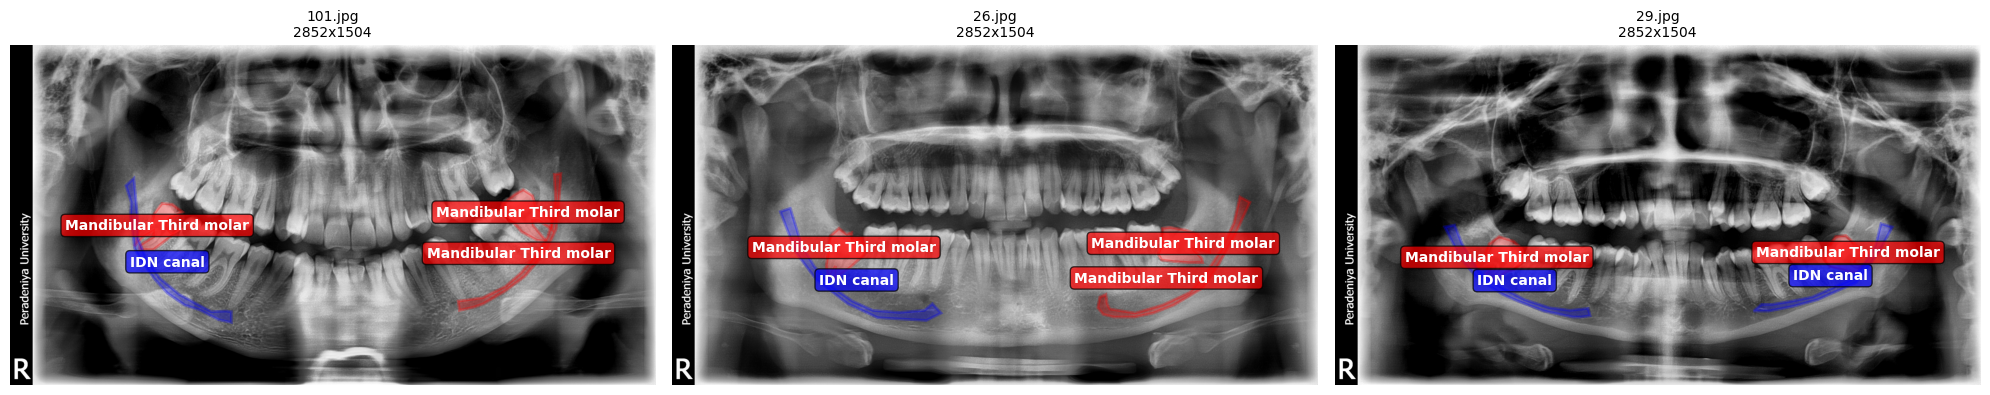

In [ ]:
def visualize_yolo_sample(image_path, label_path, class_names, num_samples=3):
    """
    Visualize YOLO format annotations.
    """
    fig, axes = plt.subplots(1, num_samples, figsize=(20, 6))
    if num_samples == 1:
        axes = [axes]

    colors = ['red', 'blue', 'green', 'yellow', 'cyan']

    # Get random samples
    image_files = sorted(os.listdir(image_path))[:num_samples]

    for idx, img_file in enumerate(image_files):
        # Load image
        img = cv2.imread(os.path.join(image_path, img_file))
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        h, w = img.shape[:2]

        # Load label
        label_file = os.path.splitext(img_file)[0] + '.txt'
        label_file_path = os.path.join(label_path, label_file)

        ax = axes[idx]
        ax.imshow(img)

        if os.path.exists(label_file_path):
            with open(label_file_path, 'r') as f:
                for line in f:
                    parts = line.strip().split()
                    class_id = int(parts[0])
                    coords = [float(x) for x in parts[1:]]

                    # Denormalize coordinates
                    points = []
                    for i in range(0, len(coords), 2):
                        x = coords[i] * w
                        y = coords[i + 1] * h
                        points.append([x, y])

                    points = np.array(points)

                    # Draw polygon
                    color = colors[class_id % len(colors)]
                    polygon = patches.Polygon(points, linewidth=2,
                                            edgecolor=color,
                                            facecolor=color,
                                            alpha=0.3)
                    ax.add_patch(polygon)

                    # Add label
                    centroid = points.mean(axis=0)
                    ax.text(centroid[0], centroid[1], class_names[class_id],
                           bbox=dict(boxstyle='round,pad=0.3',
                                   facecolor=color, alpha=0.7),
                           fontsize=10, color='white', weight='bold',
                           ha='center')

        ax.set_title(f"{img_file}\n{w}x{h}", fontsize=10)
        ax.axis('off')

    plt.tight_layout()
    plt.show()

# Visualize training samples
print("Training Set Samples:")
visualize_yolo_sample(
    os.path.join(OUTPUT_DIR, 'images', 'train'),
    os.path.join(OUTPUT_DIR, 'labels', 'train'),
    data_yaml['names'],
    num_samples=3
)

## 9. Initialize YOLOv8s-seg Model

In [ ]:
# Load YOLOv8s-seg model (pretrained on COCO)
model = YOLO('yolov8s-seg.pt')

print("✓ YOLOv8s-seg model loaded successfully!")
print(f"Model architecture: {model.model}")

✓ YOLOv8s-seg model loaded successfully!
Model architecture: SegmentationModel(
  (model): Sequential(
    (0): Conv(
      (conv): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (bn): BatchNorm2d(32, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
      (act): SiLU(inplace=True)
    )
    (1): Conv(
      (conv): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (bn): BatchNorm2d(64, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
      (act): SiLU(inplace=True)
    )
    (2): C2f(
      (cv1): Conv(
        (conv): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn): BatchNorm2d(64, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
        (act): SiLU(inplace=True)
      )
      (cv2): Conv(
        (conv): Conv2d(96, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn): BatchNorm2d(64, eps=0.001, momentum=0.03, affine=True, track_ru

## 10. Training Configuration

Key hyperparameters for achieving your target of >85% Dice coefficient and <30s processing time.

In [ ]:
# Training hyperparameters
TRAINING_CONFIG = {
    'data': data_yaml_path,
    'epochs': 150,
    'imgsz': 640,  # Image size
    'batch': 16,   # Adjust based on GPU memory (8, 16, or 32)
    'device': 0,   # GPU device (0 for first GPU, 'cpu' for CPU)
    'optimizer': 'AdamW',
    'lr0': 0.001,  # Initial learning rate
    'lrf': 0.01,   # Final learning rate (lr0 * lrf)
    'momentum': 0.937,
    'weight_decay': 0.0005,
    'warmup_epochs': 3.0,
    'warmup_momentum': 0.8,
    'warmup_bias_lr': 0.1,
    'box': 7.5,    # Box loss weight
    'cls': 0.5,    # Classification loss weight
    'dfl': 1.5,    # Distribution focal loss weight
    'pose': 12.0,  # Pose loss weight
    'kobj': 1.0,   # Keypoint objectness loss weight
    'label_smoothing': 0.0,
    'nbs': 64,     # Nominal batch size
    'hsv_h': 0.015,  # HSV-Hue augmentation
    'hsv_s': 0.7,    # HSV-Saturation augmentation
    'hsv_v': 0.4,    # HSV-Value augmentation
    'degrees': 0.0,  # Rotation augmentation
    'translate': 0.1,  # Translation augmentation
    'scale': 0.5,    # Scale augmentation
    'shear': 0.0,    # Shear augmentation
    'perspective': 0.0,  # Perspective augmentation
    'flipud': 0.0,   # Vertical flip probability
    'fliplr': 0.5,   # Horizontal flip probability
    'mosaic': 1.0,   # Mosaic augmentation probability
    'mixup': 0.0,    # Mixup augmentation probability
    'copy_paste': 0.0,  # Copy-paste augmentation probability
    'patience': 50,  # Early stopping patience
    'save': True,
    'save_period': -1,  # Save checkpoint every x epochs (-1 to disable)
    'cache': False,  # Cache images for faster training (True/False/'ram'/'disk')
    'workers': 8,    # Number of worker threads
    'project': MODEL_SAVE_DIR,
    'name': 'yolov8s_seg_seed42',
    'exist_ok': True,
    'pretrained': True,
    'verbose': True,
    'seed': 42,
    'deterministic': True,
}

print("Training Configuration:")
print("=" * 80)
for key, value in TRAINING_CONFIG.items():
    print(f"  {key}: {value}")
print("=" * 80)

Training Configuration:
  data: /content/yolo_dataset/data.yaml
  epochs: 150
  imgsz: 640
  batch: 16
  device: 0
  optimizer: AdamW
  lr0: 0.001
  lrf: 0.01
  momentum: 0.937
  weight_decay: 0.0005
  warmup_epochs: 3.0
  warmup_momentum: 0.8
  warmup_bias_lr: 0.1
  box: 7.5
  cls: 0.5
  dfl: 1.5
  pose: 12.0
  kobj: 1.0
  label_smoothing: 0.0
  nbs: 64
  hsv_h: 0.015
  hsv_s: 0.7
  hsv_v: 0.4
  degrees: 0.0
  translate: 0.1
  scale: 0.5
  shear: 0.0
  perspective: 0.0
  flipud: 0.0
  fliplr: 0.5
  mosaic: 1.0
  mixup: 0.0
  copy_paste: 0.0
  patience: 50
  save: True
  save_period: -1
  cache: False
  workers: 8
  project: /content/drive/MyDrive/FINAL_YEAR/Models/YOLOv8s_seg
  name: yolov8s_seg_seed42
  exist_ok: True
  pretrained: True
  verbose: True
  seed: 42
  deterministic: True


## 11. Train YOLOv8s-seg Model

This cell will train the model. Training progress will be displayed in real-time.

In [ ]:
# Train the model
results = model.train(**TRAINING_CONFIG)

print("\n" + "=" * 80)
print("Training Complete!")
print("=" * 80)

WARNING ⚠️ 'label_smoothing' is deprecated and will be removed in the future.
Ultralytics 8.4.9 🚀 Python-3.12.12 torch-2.9.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/yolo_dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=150, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8s_seg_seed42, nbs=64, nms=Fa

## 12. Multi-Seed Training for Reproducibility

For your ablation study and to demonstrate CV < 1%, train with multiple seeds.

In [ ]:
def train_multiple_seeds(seeds=[42, 123, 456, 789, 2024]):
    """
    Train YOLOv8s-seg with multiple random seeds for reproducibility analysis.
    """
    results_dict = {}

    for seed in seeds:
        print("\n" + "=" * 80)
        print(f"Training with seed: {seed}")
        print("=" * 80)

        # Set seed
        set_seed(seed)

        # Update config
        config = TRAINING_CONFIG.copy()
        config['seed'] = seed
        config['name'] = f'yolov8s_seg_seed{seed}'

        # Initialize new model
        model_seed = YOLO('yolov8s-seg.pt')

        # Train
        results = model_seed.train(**config)

        # Store results
        results_dict[seed] = results

        print(f"✓ Completed training with seed {seed}")

    return results_dict

# Uncomment to run multi-seed training
# multi_seed_results = train_multiple_seeds(seeds=[42, 123, 456, 789, 2024])

## 13. Model Validation

In [ ]:
# Validate the trained model
metrics = model.val()

print("\nValidation Metrics:")
print("=" * 80)
print(f"mAP50-95 (box): {metrics.box.map:.4f}")
print(f"mAP50 (box): {metrics.box.map50:.4f}")
print(f"mAP75 (box): {metrics.box.map75:.4f}")
print(f"\nmAP50-95 (mask): {metrics.seg.map:.4f}")
print(f"mAP50 (mask): {metrics.seg.map50:.4f}")
print(f"mAP75 (mask): {metrics.seg.map75:.4f}")
print("=" * 80)

Ultralytics 8.4.9 🚀 Python-3.12.12 torch-2.9.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
YOLOv8s-seg summary (fused): 86 layers, 11,780,374 parameters, 0 gradients, 39.9 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3180.2±1478.2 MB/s, size: 556.4 KB)
val: Scanning /content/yolo_dataset/labels/val.cache... 37 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 37/37 19.4Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 1.2s/it 3.5s
                   all         37        153      0.991      0.961       0.98      0.795      0.943      0.915       0.93       0.48
Mandibular Third molar         37         76      0.995      0.974      0.994      0.791      0.995      0.974       0.99      0.682
             IDN canal         37         77      0.986      0.948      0.967      0.799      0.891      0.857      0.869      0.278
Speed: 5.5ms preprocess, 31.9ms inference, 0.

## 14. Calculate Clinical Metrics (Dice Coefficient)

For your clinical viability target of >85% Dice coefficient.

In [ ]:
def calculate_dice_coefficient(pred_mask, gt_mask):
    """
    Calculate Dice coefficient between predicted and ground truth masks.
    Dice = 2 * |A ∩ B| / (|A| + |B|)
    """
    intersection = np.logical_and(pred_mask, gt_mask).sum()
    union = pred_mask.sum() + gt_mask.sum()

    if union == 0:
        return 1.0 if intersection == 0 else 0.0

    dice = (2.0 * intersection) / union
    return dice


def calculate_iou(pred_mask, gt_mask):
    """
    Calculate Intersection over Union (IoU).
    IoU = |A ∩ B| / |A ∪ B|
    """
    intersection = np.logical_and(pred_mask, gt_mask).sum()
    union = np.logical_or(pred_mask, gt_mask).sum()

    if union == 0:
        return 1.0 if intersection == 0 else 0.0

    iou = intersection / union
    return iou


def evaluate_segmentation_metrics(model, test_images_dir, test_labels_dir, class_names):
    """
    Evaluate segmentation performance with clinical metrics.
    """
    dice_scores = {name: [] for name in class_names}
    iou_scores = {name: [] for name in class_names}

    test_images = sorted(os.listdir(test_images_dir))

    print("Evaluating segmentation metrics on test set...")

    for img_file in tqdm(test_images):
        img_path = os.path.join(test_images_dir, img_file)

        # Run prediction
        results = model.predict(img_path, conf=0.25, iou=0.7, verbose=False)

        if len(results) == 0 or results[0].masks is None:
            continue

        # Load ground truth
        label_file = os.path.splitext(img_file)[0] + '.txt'
        label_path = os.path.join(test_labels_dir, label_file)

        if not os.path.exists(label_path):
            continue

        # Get image dimensions
        img = cv2.imread(img_path)
        h, w = img.shape[:2]

        # Process predictions
        pred_masks = results[0].masks.data.cpu().numpy()
        pred_classes = results[0].boxes.cls.cpu().numpy().astype(int)

        # Process ground truth
        with open(label_path, 'r') as f:
            for line in f:
                parts = line.strip().split()
                gt_class = int(parts[0])
                coords = [float(x) for x in parts[1:]]

                # Create GT mask
                points = []
                for i in range(0, len(coords), 2):
                    x = int(coords[i] * w)
                    y = int(coords[i + 1] * h)
                    points.append([x, y])

                gt_mask = np.zeros((h, w), dtype=np.uint8)
                cv2.fillPoly(gt_mask, [np.array(points)], 1)

                # Find matching prediction
                matching_preds = np.where(pred_classes == gt_class)[0]

                if len(matching_preds) > 0:
                    # Use the prediction with highest IoU
                    best_iou = 0
                    best_pred_mask = None

                    for pred_idx in matching_preds:
                        pred_mask = cv2.resize(
                            pred_masks[pred_idx],
                            (w, h),
                            interpolation=cv2.INTER_NEAREST
                        )

                        current_iou = calculate_iou(pred_mask > 0.5, gt_mask)
                        if current_iou > best_iou:
                            best_iou = current_iou
                            best_pred_mask = pred_mask

                    if best_pred_mask is not None:
                        dice = calculate_dice_coefficient(best_pred_mask > 0.5, gt_mask)
                        iou = best_iou

                        dice_scores[class_names[gt_class]].append(dice)
                        iou_scores[class_names[gt_class]].append(iou)

    # Calculate statistics
    print("\n" + "=" * 80)
    print("Clinical Segmentation Metrics")
    print("=" * 80)

    all_dice = []
    all_iou = []

    for class_name in class_names:
        if len(dice_scores[class_name]) > 0:
            mean_dice = np.mean(dice_scores[class_name])
            std_dice = np.std(dice_scores[class_name])
            mean_iou = np.mean(iou_scores[class_name])
            std_iou = np.std(iou_scores[class_name])

            print(f"\n{class_name}:")
            print(f"  Dice Coefficient: {mean_dice:.4f} ± {std_dice:.4f}")
            print(f"  IoU: {mean_iou:.4f} ± {std_iou:.4f}")
            print(f"  Samples: {len(dice_scores[class_name])}")

            all_dice.extend(dice_scores[class_name])
            all_iou.extend(iou_scores[class_name])

    if len(all_dice) > 0:
        print(f"\nOverall:")
        print(f"  Mean Dice Coefficient: {np.mean(all_dice):.4f} ± {np.std(all_dice):.4f}")
        print(f"  Mean IoU: {np.mean(all_iou):.4f} ± {np.std(all_iou):.4f}")
        print(f"  Clinical Target (>85% Dice): {'✓ ACHIEVED' if np.mean(all_dice) > 0.85 else '✗ NOT MET'}")

    print("=" * 80)

    return dice_scores, iou_scores


# Run evaluation
dice_results, iou_results = evaluate_segmentation_metrics(
    model,
    os.path.join(OUTPUT_DIR, 'images', 'test'),
    os.path.join(OUTPUT_DIR, 'labels', 'test'),
    data_yaml['names']
)

Evaluating segmentation metrics on test set...


  0%|          | 0/38 [00:00<?, ?it/s]


Clinical Segmentation Metrics

Mandibular Third molar:
  Dice Coefficient: 0.8568 ± 0.1022
  IoU: 0.7583 ± 0.1020
  Samples: 77

IDN canal:
  Dice Coefficient: 0.6375 ± 0.1093
  IoU: 0.4772 ± 0.1157
  Samples: 74

Overall:
  Mean Dice Coefficient: 0.7493 ± 0.1523
  Mean IoU: 0.6205 ± 0.1778
  Clinical Target (>85% Dice): ✗ NOT MET


## 15. Inference Time Analysis

For your clinical target of <30 seconds processing time.

Measuring inference time on 50 test images...


  0%|          | 0/38 [00:00<?, ?it/s]


Inference Time Analysis
Mean inference time: 0.042s ± 0.007s
Min: 0.035s
Max: 0.062s

Clinical Target (<30s): ✓ ACHIEVED
Throughput: 23.89 images/second


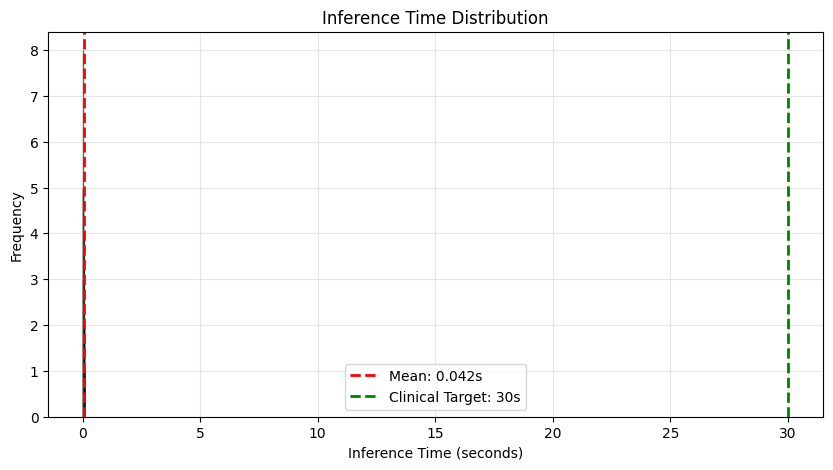

In [ ]:
import time

def measure_inference_time(model, test_images_dir, num_samples=50):
    """
    Measure inference time to validate <30s clinical requirement.
    """
    test_images = sorted(os.listdir(test_images_dir))[:num_samples]
    inference_times = []

    print(f"Measuring inference time on {num_samples} test images...")

    for img_file in tqdm(test_images):
        img_path = os.path.join(test_images_dir, img_file)

        start_time = time.time()
        results = model.predict(img_path, conf=0.25, iou=0.7, verbose=False)
        end_time = time.time()

        inference_time = end_time - start_time
        inference_times.append(inference_time)

    mean_time = np.mean(inference_times)
    std_time = np.std(inference_times)
    min_time = np.min(inference_times)
    max_time = np.max(inference_times)

    print("\n" + "=" * 80)
    print("Inference Time Analysis")
    print("=" * 80)
    print(f"Mean inference time: {mean_time:.3f}s ± {std_time:.3f}s")
    print(f"Min: {min_time:.3f}s")
    print(f"Max: {max_time:.3f}s")
    print(f"\nClinical Target (<30s): {'✓ ACHIEVED' if mean_time < 30 else '✗ NOT MET'}")
    print(f"Throughput: {1/mean_time:.2f} images/second")
    print("=" * 80)

    # Plot distribution
    plt.figure(figsize=(10, 5))
    plt.hist(inference_times, bins=30, edgecolor='black', alpha=0.7)
    plt.axvline(mean_time, color='red', linestyle='--', linewidth=2, label=f'Mean: {mean_time:.3f}s')
    plt.axvline(30, color='green', linestyle='--', linewidth=2, label='Clinical Target: 30s')
    plt.xlabel('Inference Time (seconds)')
    plt.ylabel('Frequency')
    plt.title('Inference Time Distribution')
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

    return inference_times

# Measure inference time
inference_times = measure_inference_time(
    model,
    os.path.join(OUTPUT_DIR, 'images', 'test'),
    num_samples=50
)

## 16. Visualize Predictions

Test Set Predictions:


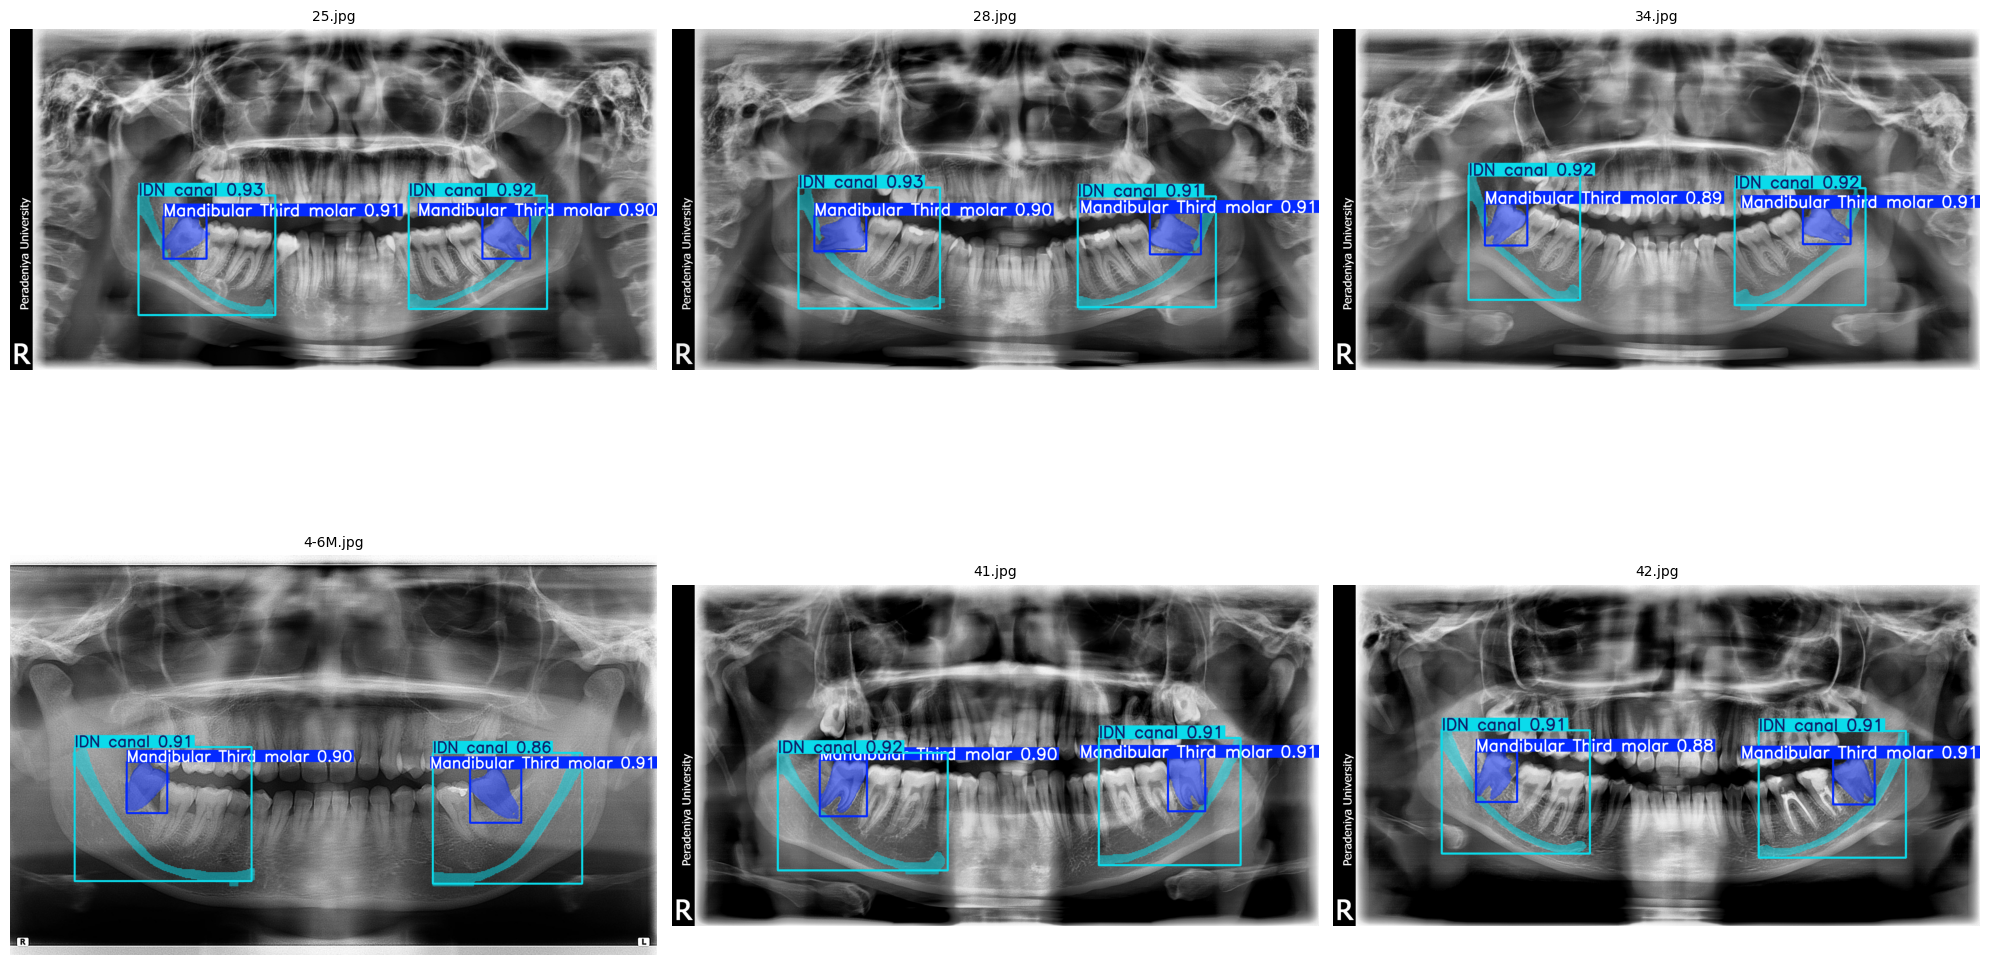

In [ ]:
def visualize_predictions(model, test_images_dir, num_samples=6):
    """
    Visualize model predictions on test images.
    """
    test_images = sorted(os.listdir(test_images_dir))[:num_samples]

    fig, axes = plt.subplots(2, 3, figsize=(20, 13))
    axes = axes.flatten()

    for idx, img_file in enumerate(test_images):
        if idx >= len(axes):
            break

        img_path = os.path.join(test_images_dir, img_file)

        # Run prediction
        results = model.predict(img_path, conf=0.25, iou=0.7, verbose=False)

        # Plot
        if len(results) > 0 and results[0].plot is not None:
            annotated_img = results[0].plot()
            annotated_img = cv2.cvtColor(annotated_img, cv2.COLOR_BGR2RGB)
        else:
            annotated_img = cv2.imread(img_path)
            annotated_img = cv2.cvtColor(annotated_img, cv2.COLOR_BGR2RGB)

        axes[idx].imshow(annotated_img)
        axes[idx].set_title(img_file, fontsize=10)
        axes[idx].axis('off')

    plt.tight_layout()
    plt.show()

# Visualize predictions
print("Test Set Predictions:")
visualize_predictions(
    model,
    os.path.join(OUTPUT_DIR, 'images', 'test'),
    num_samples=6
)

## 17. Export Model for Deployment

In [ ]:
# Export to ONNX for deployment
model.export(format='onnx', imgsz=640)

print("✓ Model exported to ONNX format for deployment")

# Save best model to Google Drive
best_model_path = os.path.join(MODEL_SAVE_DIR, 'yolov8s_seg_seed42', 'weights', 'best.pt')
if os.path.exists(best_model_path):
    print(f"✓ Best model saved at: {best_model_path}")
else:
    print("⚠ Best model path not found")

Ultralytics 8.4.9 🚀 Python-3.12.12 torch-2.9.0+cu126 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino/

PyTorch: starting from '/content/drive/MyDrive/FINAL_YEAR/Models/YOLOv8s_seg/yolov8s_seg_seed42/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) ((1, 38, 8400), (1, 32, 160, 160)) (22.7 MB)
requirements: Ultralytics requirements ['onnx>=1.12.0,<2.0.0', 'onnxslim>=0.1.71', 'onnxruntime-gpu'] not found, attempting AutoUpdate...
Using Python 3.12.12 environment at: /usr
Resolved 14 packages in 189ms
Prepared 6 packages in 4.73s
Installed 6 packages in 422ms
 + colorama==0.4.6
 + coloredlogs==15.0.1
 + humanfriendly==10.0
 + onnx==1.20.1
 + onnxruntime-gpu==1.23.2
 + onnxslim==0.1.82

requirements: AutoUpdate success ✅ 6.0s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


ONNX: starting export with onnx

/usr/local/lib/python3.12/dist-packages/torch/onnx/_internal/torchscript_exporter/utils.py:1447: OnnxExporterWarning: Exporting to ONNX opset version 22 is not supported. by 'torch.onnx.export()'. The highest opset version supported is 20. To use a newer opset version, consider 'torch.onnx.export(..., dynamo=True)'. 
  warnings.warn(


ONNX: slimming with onnxslim 0.1.82...
ONNX: export success ✅ 9.5s, saved as '/content/drive/MyDrive/FINAL_YEAR/Models/YOLOv8s_seg/yolov8s_seg_seed42/weights/best.onnx' (45.2 MB)

Export complete (10.7s)
Results saved to /content/drive/MyDrive/FINAL_YEAR/Models/YOLOv8s_seg/yolov8s_seg_seed42/weights
Predict:         yolo predict task=segment model=/content/drive/MyDrive/FINAL_YEAR/Models/YOLOv8s_seg/yolov8s_seg_seed42/weights/best.onnx imgsz=640 
Validate:        yolo val task=segment model=/content/drive/MyDrive/FINAL_YEAR/Models/YOLOv8s_seg/yolov8s_seg_seed42/weights/best.onnx imgsz=640 data=/content/yolo_dataset/data.yaml  
Visualize:       https://netron.app
✓ Model exported to ONNX format for deployment
✓ Best model saved at: /content/drive/MyDrive/FINAL_YEAR/Models/YOLOv8s_seg/yolov8s_seg_seed42/weights/best.pt


## 18. Generate Comprehensive Report

In [ ]:
def generate_report(metrics, dice_results, iou_results, inference_times, class_names):
    """
    Generate comprehensive performance report for thesis.
    """
    report = []
    report.append("=" * 80)
    report.append("YOLOv8s-seg Performance Report")
    report.append("IAN Canal & Mandibular Third Molar Segmentation")
    report.append("=" * 80)
    report.append("")

    # Detection Metrics
    report.append("1. Detection Metrics (COCO):")
    report.append(f"   mAP50-95 (box): {metrics.box.map:.4f}")
    report.append(f"   mAP50 (box): {metrics.box.map50:.4f}")
    report.append(f"   mAP75 (box): {metrics.box.map75:.4f}")
    report.append("")

    # Segmentation Metrics
    report.append("2. Segmentation Metrics (COCO):")
    report.append(f"   mAP50-95 (mask): {metrics.seg.map:.4f}")
    report.append(f"   mAP50 (mask): {metrics.seg.map50:.4f}")
    report.append(f"   mAP75 (mask): {metrics.seg.map75:.4f}")
    report.append("")

    # Clinical Metrics
    report.append("3. Clinical Metrics:")
    all_dice = []
    all_iou = []

    for class_name in class_names:
        if len(dice_results[class_name]) > 0:
            mean_dice = np.mean(dice_results[class_name])
            std_dice = np.std(dice_results[class_name])
            mean_iou = np.mean(iou_results[class_name])
            std_iou = np.std(iou_results[class_name])

            report.append(f"   {class_name}:")
            report.append(f"     Dice: {mean_dice:.4f} ± {std_dice:.4f}")
            report.append(f"     IoU: {mean_iou:.4f} ± {std_iou:.4f}")

            all_dice.extend(dice_results[class_name])
            all_iou.extend(iou_results[class_name])

    report.append(f"   Overall Dice: {np.mean(all_dice):.4f} ± {np.std(all_dice):.4f}")
    report.append(f"   Overall IoU: {np.mean(all_iou):.4f} ± {np.std(all_iou):.4f}")
    report.append("")

    # Inference Time
    report.append("4. Inference Performance:")
    report.append(f"   Mean time: {np.mean(inference_times):.3f}s ± {np.std(inference_times):.3f}s")
    report.append(f"   Min: {np.min(inference_times):.3f}s")
    report.append(f"   Max: {np.max(inference_times):.3f}s")
    report.append(f"   Throughput: {1/np.mean(inference_times):.2f} images/second")
    report.append("")

    # Clinical Targets
    report.append("5. Clinical Viability Assessment:")
    dice_target = np.mean(all_dice) > 0.85
    time_target = np.mean(inference_times) < 30
    report.append(f"   Dice Coefficient >85%: {'✓ ACHIEVED' if dice_target else '✗ NOT MET'} ({np.mean(all_dice)*100:.2f}%)")
    report.append(f"   Processing Time <30s: {'✓ ACHIEVED' if time_target else '✗ NOT MET'} ({np.mean(inference_times):.2f}s)")
    report.append(f"   Clinical Deployment Ready: {'✓ YES' if dice_target and time_target else '✗ NO'}")
    report.append("")

    report.append("=" * 80)

    report_text = "\n".join(report)
    print(report_text)

    # Save to file
    report_path = os.path.join(MODEL_SAVE_DIR, 'performance_report.txt')
    with open(report_path, 'w') as f:
        f.write(report_text)

    print(f"\n✓ Report saved to: {report_path}")

    return report_text

# Generate report
report = generate_report(metrics, dice_results, iou_results, inference_times, data_yaml['names'])

YOLOv8s-seg Performance Report
IAN Canal & Mandibular Third Molar Segmentation

1. Detection Metrics (COCO):
   mAP50-95 (box): 0.7952
   mAP50 (box): 0.9803
   mAP75 (box): 0.9702

2. Segmentation Metrics (COCO):
   mAP50-95 (mask): 0.4799
   mAP50 (mask): 0.9299
   mAP75 (mask): 0.4782

3. Clinical Metrics:
   Mandibular Third molar:
     Dice: 0.8568 ± 0.1022
     IoU: 0.7583 ± 0.1020
   IDN canal:
     Dice: 0.6375 ± 0.1093
     IoU: 0.4772 ± 0.1157
   Overall Dice: 0.7493 ± 0.1523
   Overall IoU: 0.6205 ± 0.1778

4. Inference Performance:
   Mean time: 0.042s ± 0.007s
   Min: 0.035s
   Max: 0.062s
   Throughput: 23.89 images/second

5. Clinical Viability Assessment:
   Dice Coefficient >85%: ✗ NOT MET (74.93%)
   Processing Time <30s: ✓ ACHIEVED (0.04s)
   Clinical Deployment Ready: ✗ NO


✓ Report saved to: /content/drive/MyDrive/FINAL_YEAR/Models/YOLOv8s_seg/performance_report.txt


## 19. Save Results for Ablation Study

In [ ]:
# Save results to CSV for analysis
results_df = pd.DataFrame({
    'Model': ['YOLOv8s-seg'],
    'mAP50-95_box': [metrics.box.map],
    'mAP50_box': [metrics.box.map50],
    'mAP50-95_mask': [metrics.seg.map],
    'mAP50_mask': [metrics.seg.map50],
    'Dice_mean': [np.mean([v for vals in dice_results.values() for v in vals])],
    'Dice_std': [np.std([v for vals in dice_results.values() for v in vals])],
    'IoU_mean': [np.mean([v for vals in iou_results.values() for v in vals])],
    'IoU_std': [np.std([v for vals in iou_results.values() for v in vals])],
    'Inference_time_mean': [np.mean(inference_times)],
    'Inference_time_std': [np.std(inference_times)],
    'Seed': [42]
})

results_csv_path = os.path.join(MODEL_SAVE_DIR, 'yolov8s_seg_results.csv')
results_df.to_csv(results_csv_path, index=False)

print(f"✓ Results saved to: {results_csv_path}")
print("\nResults DataFrame:")
display(results_df)

✓ Results saved to: /content/drive/MyDrive/FINAL_YEAR/Models/YOLOv8s_seg/yolov8s_seg_results.csv

Results DataFrame:


,Model,mAP50-95_box,mAP50_box,mAP50-95_mask,mAP50_mask,Dice_mean,Dice_std,IoU_mean,IoU_std,Inference_time_mean,Inference_time_std,Seed
0,YOLOv8s-seg,0.79522,0.980317,0.479875,0.929932,0.749316,0.152318,0.620538,0.17782,0.041866,0.006755,42


## 20. Next Steps

### For Your Ablation Study (as requested by Dr. Yapa):

1. **Repeat this training with other architectures** (U-Net, Attention U-Net, DeepLabv3+, etc.)
2. **Compare unified vs. sequential pipeline approaches**
3. **Component-level ablations**: Test with/without focal loss, CLAHE preprocessing, data augmentation
4. **Multi-seed validation**: Run with seeds [42, 123, 456, 789, 2024] to calculate CV

### For Integration with Classification Task:

1. Use segmented regions as input to risk classification network
2. Implement uncertainty quantification module
3. Build end-to-end unified multi-task framework

### For Thesis Documentation:

1. Generate confusion matrices and class-wise performance
2. Create qualitative result visualizations
3. Document failure cases and edge scenarios
4. Prepare deployment-ready model artifacts

---

**Remember to:**
- Save trained models to Google Drive regularly
- Document hyperparameter choices and their rationale
- Keep track of all experimental configurations for reproducibility
- Prepare comprehensive visualizations for your defense presentation